# Modelagem Matemática e Computacional — CitizenTech
**Projeto:** Otimização Inteligente da Frota Municipal de Ônibus  
### Integrantes do Grupo
* **Pedro Henrique Neves** — RM: `[571382]`
* **Akin Alexandre Mendes Martins** — RM: `[572773]`
* **Maria Eduarda Rocha Benjamim** — RM: `[570554]`

### Contextualização
Este projeto aplica **sistemas lineares, matrizes e transformações lineares** em Python para reconstruir a distribuição atual de uma frota de **72 ônibus** entre quatro regiões (Norte, Sul, Leste e Oeste) e propor uma política de redistribuição que elimine a superlotação no horário de pico.

---

## ETAPA 1 — Diagnóstico e Modelagem da Situação Atual (5,0 pontos)

* **1.a. Variáveis do Problema:**
  * $N$: quantidade de ônibus alocados na região **Norte** ($N \in \mathbb{Z}_+$)
  * $S$: quantidade de ônibus alocados na região **Sul** ($S \in \mathbb{Z}_+$)
  * $L$: quantidade de ônibus alocados na região **Leste** ($L \in \mathbb{Z}_+$)
  * $O$: quantidade de ônibus alocados na região **Oeste** ($O \in \mathbb{Z}_+$)

* **1.b. Modelo Matemático (Sistema Linear):**
  $$\begin{cases}
  N + S + L + O = 72 \\
  N + 2S + O = 76 \\
  S + 2L = 52 \\
  N + L + 2O = 76
  \end{cases}$$

* **1.c. Representação Matricial ($A \cdot \mathbf{x} = \mathbf{b}$):**
  $$\begin{bmatrix} 1 & 1 & 1 & 1 \\ 1 & 2 & 0 & 1 \\ 0 & 1 & 2 & 0 \\ 1 & 0 & 1 & 2 \end{bmatrix} \cdot \begin{bmatrix} N \\ S \\ L \\ O \end{bmatrix} = \begin{bmatrix} 72 \\ 76 \\ 52 \\ 76 \end{bmatrix}$$

* **1.d. Investigação de Unicidade (Álgebra Linear):**
  Calculando o determinante da matriz dos coeficientes $A$, obtemos **$\det(A) = 3 \neq 0$**. Como o determinante é diferente de zero, a matriz $A$ é invertível e possui posto completo ($\text{posto}(A) = \text{posto}([A|\mathbf{b}]) = 4$). Pelo Teorema de Rouché-Capelli, o sistema é **Possível e Determinado (SPD)**, garantindo que existe uma **única distribuição válida** de ônibus.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# === ETAPA 1: DIAGNÓSTICO E SITUAÇÃO ATUAL ===
# Matriz dos coeficientes A (Colunas: Norte, Sul, Leste, Oeste)
A = np.array([
    [1, 1, 1, 1],
    [1, 2, 0, 1],
    [0, 1, 2, 0],
    [1, 0, 1, 2]
], dtype=float)

# Vetor de resultados operacionais b
b = np.array([72, 76, 52, 76], dtype=float)

# 1.d. Investigação de unicidade (Determinante e Posto)
det_A = np.linalg.det(A)
posto_A = np.linalg.matrix_rank(A)
posto_ampliada = np.linalg.matrix_rank(np.column_stack((A, b)))

print("=== INVESTIGAÇÃO MATEMÁTICA (ÁLGEBRA LINEAR) ===")
print(f"Determinante de A: {det_A:.2f} (Diferente de zero -> Matriz Invertível)")
print(f"Posto de A: {posto_A} | Posto da Matriz Aumentada: {posto_ampliada}")
print("Conclusão: Sistema Possível e Determinado (SPD) -> Solução Única garantida.\n")

# 1.e. Resolução do sistema linear A * x = b
frota_atual = np.linalg.solve(A, b)
frota_atual = np.round(frota_atual).astype(int)

regioes = ['Norte', 'Sul', 'Leste', 'Oeste']
print("=== DISTRIBUIÇÃO ATUAL RECONSTRUÍDA ===")
for reg, qtd in zip(regioes, frota_atual):
    print(f"Região {reg}: {qtd} ônibus")

# 1.f. Verificação (Prova Real: A @ x == b)
verificacao = A @ frota_atual
print("\n=== VERIFICAÇÃO DOS REGISTROS OPERACIONAIS ===")
print("Calculado (A * x):", verificacao.astype(int))
print("Esperado (b):     ", b.astype(int))
assert np.allclose(verificacao, b), "Erro: A solução não satisfaz o sistema!"
print("Sucesso: Todos os registros operacionais foram perfeitamente satisfeitos!")


=== INVESTIGAÇÃO MATEMÁTICA (ÁLGEBRA LINEAR) ===
Determinante de A: 3.00 (Diferente de zero -> Matriz Invertível)
Posto de A: 4 | Posto da Matriz Aumentada: 4
Conclusão: Sistema Possível e Determinado (SPD) -> Solução Única garantida.

=== DISTRIBUIÇÃO ATUAL RECONSTRUÍDA ===
Região Norte: 12 ônibus
Região Sul: 20 ônibus
Região Leste: 16 ônibus
Região Oeste: 24 ônibus

=== VERIFICAÇÃO DOS REGISTROS OPERACIONAIS ===
Calculado (A * x): [72 76 52 76]
Esperado (b):      [72 76 52 76]
Sucesso: Todos os registros operacionais foram perfeitamente satisfeitos!


---

## ETAPA 2 — Política de Redistribuição e Transformação Linear (5,0 pontos)

* **2.a e 2.b. Análise de Demanda e Diagnóstico de Desequilíbrios (Capacidade = 40 pass./ônibus):**
  * **Norte:** $560 / 40 = 14$ necessários | Atual: $12$ $\rightarrow$ **Déficit de -2 ônibus** (superlotação)
  * **Sul:** $760 / 40 = 19$ necessários | Atual: $20$ $\rightarrow$ **Excedente de +1 ônibus** (ocioso)
  * **Leste:** $720 / 40 = 18$ necessários | Atual: $16$ $\rightarrow$ **Déficit de -2 ônibus** (superlotação)
  * **Oeste:** $840 / 40 = 21$ necessários | Atual: $24$ $\rightarrow$ **Excedente de +3 ônibus** (ocioso)

* **2.c. Critérios da Política de Redistribuição:**
  Para eliminar 100% da superlotação sem ampliar a frota total de 72 veículos, os centros operacionais com excedente transferem veículos para os centros deficitários:
  1. A região **Sul** (20 ônibus) mantém $95\%$ de sua frota ($19$ ônibus) e transfere $5\%$ ($1$ ônibus) para a região **Norte**.
  2. A região **Oeste** (24 ônibus) mantém $87,5\%$ ($21/24 = 21$ ônibus) e transfere $1/24$ ($1$ ônibus) para a região **Norte** e $2/24$ ($2$ ônibus) para a região **Leste**.
  3. As regiões **Norte** e **Leste** mantêm $100\%$ de suas frotas atuais e recebem os reforços.

* **2.d e 2.e. Transformação Linear $T(\mathbf{x}) = M \cdot \mathbf{x}$ e Significado dos Coeficientes:**
  $$M = \begin{bmatrix}
  1 & 1/20 & 0 & 1/24 \\
  0 & 19/20 & 0 & 0 \\
  0 & 0 & 1 & 2/24 \\
  0 & 0 & 0 & 21/24
  \end{bmatrix} = \begin{bmatrix}
  1.00 & 0.05 & 0.00 & 0.0417 \\
  0.00 & 0.95 & 0.00 & 0.0000 \\
  0.00 & 0.00 & 1.00 & 0.0833 \\
  0.00 & 0.00 & 0.00 & 0.8750
  \end{bmatrix}$$
  * **Significado de $m_{ij}$:** Cada coeficiente $m_{ij}$ representa a **fração (proporção) da frota da região $j$ (coluna) que é alocada para a região $i$ (linha)**. Elementos da diagonal principal ($m_{ii}$) indicam o percentual retido na própria região, enquanto elementos fora da diagonal ($m_{ij}, i \neq j$) indicam o percentual compartilhado entre centros.

* **2.f. Demonstração Matemática das Propriedades:**
  1. **Não negatividade ($T(\mathbf{x}) \geq \mathbf{0}$):** Como o vetor inicial possui entradas não negativas ($x_j \geq 0$) e todos os coeficientes da matriz satisfazem $m_{ij} \geq 0$, cada componente da nova frota $y_i = \sum_{j=1}^{4} m_{ij} x_j$ é uma soma de produtos de números não negativos, garantindo $y_i \geq 0$.
  2. **Preservação da frota total ($\sum y_i = \sum x_j = 72$):** A matriz $M$ é uma **matriz estocástica por colunas**, pois a soma de cada coluna é exatamente igual a $1$ ($\sum_{i=1}^{4} m_{ij} = 1$ para todo $j$). Logo:
     $$\sum_{i=1}^{4} y_i = \sum_{i=1}^{4} \left(\sum_{j=1}^{4} m_{ij} x_j\right) = \sum_{j=1}^{4} x_j \left(\sum_{i=1}^{4} m_{ij}\right) = \sum_{j=1}^{4} x_j \cdot 1 = 72$$


In [ ]:
# === ETAPA 2: DEMANDA E POLÍTICA DE REDISTRIBUIÇÃO ===
passageiros = np.array([560, 760, 720, 840])
capacidade_onibus = 40

# Estimativa de ônibus necessários por região
frota_necessaria = (passageiros / capacidade_onibus).astype(int)
desequilibrio_antes = frota_atual - frota_necessaria

# Matriz de Transformação Linear M (Valores fracionários exatos)
M = np.array([
    [1.0,  1/20, 0.0,  1/24],
    [0.0, 19/20, 0.0,  0.00],
    [0.0,  0.00, 1.0,  2/24],
    [0.0,  0.00, 0.0, 21/24]
])

# Aplicação da Transformação Linear: T(x) = M * x
frota_redistribuida = np.round(M @ frota_atual).astype(int)
desequilibrio_depois = frota_redistribuida - frota_necessaria

# Verificação computacional das propriedades da transformação
soma_colunas = np.sum(M, axis=0)
preserva_total = (np.sum(frota_redistribuida) == np.sum(frota_atual))
nao_negativa = np.all(M >= 0) and np.all(frota_redistribuida >= 0)

print("=== PROPRIEDADES DA TRANSFORMAÇÃO LINEAR ===")
print(f"Soma de cada coluna de M: {soma_colunas}")
print(f"Frota total antes: {np.sum(frota_atual)} | Frota total depois: {np.sum(frota_redistribuida)}")
print(f"Preserva quantidade total de ônibus? {'Sim' if preserva_total else 'Não'}")
print(f"Garante alocações não negativas?      {'Sim' if nao_negativa else 'Não'}\n")

# Tabela Comparativa Consolidada
df_resultado = pd.DataFrame({
    'Região': regioes,
    'Passageiros (Pico)': passageiros,
    'Frota Atual': frota_atual,
    'Frota Necessária': frota_necessaria,
    'Saldo Antes': desequilibrio_antes,
    'Frota Redistribuída': frota_redistribuida,
    'Saldo Depois': desequilibrio_depois
})



=== PROPRIEDADES DA TRANSFORMAÇÃO LINEAR ===
Soma de cada coluna de M: [1. 1. 1. 1.]
Frota total antes: 72 | Frota total depois: 72
Preserva quantidade total de ônibus? Sim
Garante alocações não negativas?      Sim



In [ ]:
print("=== DIAGNÓSTICO E RESULTADO DA INTERVENÇÃO ===")
display(df_resultado)


=== DIAGNÓSTICO E RESULTADO DA INTERVENÇÃO ===


,Região,Passageiros (Pico),Frota Atual,Frota Necessária,Saldo Antes,Frota Redistribuída,Saldo Depois
0,Norte,560,12,14,-2,14,0
1,Sul,760,20,19,1,19,0
2,Leste,720,16,18,-2,18,0
3,Oeste,840,24,21,3,21,0


### Visualização Comparativa da Frota
Gráfico comparando a alocação inicial, a demanda ideal no horário de pico e a nova distribuição após a aplicação da transformação linear.


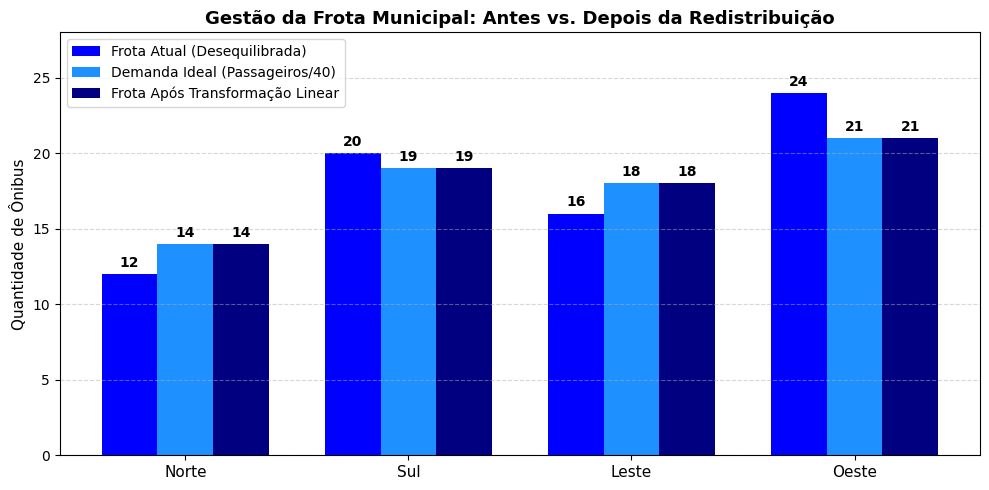

In [ ]:
# === VISUALIZAÇÃO DOS RESULTADOS ===
x = np.arange(len(regioes))
largura = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - largura, frota_atual, largura, label='Frota Atual (Desequilibrada)', color='#0000FF')
rects2 = ax.bar(x, frota_necessaria, largura, label='Demanda Ideal (Passageiros/40)', color='#1E90FF')
rects3 = ax.bar(x + largura, frota_redistribuida, largura, label='Frota Após Transformação Linear', color='#000080')

ax.set_title('Gestão da Frota Municipal: Antes vs. Depois da Redistribuição', fontsize=13, fontweight='bold')
ax.set_ylabel('Quantidade de Ônibus', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(regioes, fontsize=11)
ax.set_ylim(0, 28)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

for rects in [rects1, rects2, rects3]:
    for rect in rects:
        altura = rect.get_height()
        ax.annotate(f'{altura}',
                    xy=(rect.get_x() + rect.get_width() / 2, altura),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()